## **Проектная работа №1: Классификация объектов на изображении**









### **Цель:**


Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.


### **Базовая реализация:**



1. **Сбор изображения:**
   - Используйте камеру или загрузите готовое изображение с монетами для обработки.

2. **Предварительная обработка изображения:**
   - Преобразуйте изображение в оттенки серого.
   - Примените размытие Гаусса для уменьшения шума.
   - Используйте оператор Кэнни для обнаружения краев.

3. **Обнаружение кругов (монет):**
   - Используйте преобразование Хафа для обнаружения кругов на изображении.
   - Получите координаты центров и радиусов обнаруженных кругов (монет).

4. **Классификация монет:**
   - Определите номинал каждой монеты на основе ее радиуса.
   - Установите пороговые значения для радиусов, соответствующие разным номиналам:
     - **Маленький радиус:** 1 рубль.
     - **Средний радиус:** 2 рубля.
     - **Большой радиус:** 5 рублей.

5. **Подсчет общей суммы:**
   - Суммируйте номиналы всех обнаруженных монет.
   - Отобразите общую сумму на изображении или в консоли.

6. **Отображение результатов:**
   - Нарисуйте окружности на изображении вокруг обнаруженных монет.
   - Подпишите рядом с каждой монетой ее номинал.
   - Покажите исходное изображение с отмеченными монетами.
   - Выведите обработанные этапы для визуализации процесса (например, изображение после предварительной обработки, с контурами и т.д.).



### **Требования к реализации:**



- Использовать только библиотеку **OpenCV** и стандартные библиотеки Python (например, **NumPy**).
- Код должен быть хорошо документирован с комментариями для каждого основного блока.
- Предусмотреть возможность настройки параметров обработки через трекбары или отдельные переменные.



### **Рекомендации:**




- **Преобразование Хафа** для кругов является удобным инструментом для обнаружения круглых объектов на изображении.
- **Пороговые значения радиусов** необходимо подобрать экспериментально, протестировав на образцах монет разных номиналов.
- **Обработка перекрывающихся монет** может потребовать более сложных алгоритмов, таких как водоразделение или использование градиентных признаков.
- Тестируйте программу на различных изображениях с разным количеством и расположением монет, а также при разном освещении.





### **Ожидаемый результат:**




В результате выполнения задания вы получите программу, которая способна:

- Принимать на вход изображение с монетами.
- Обрабатывать изображение и обнаруживать монеты без использования библиотеки cvzone.
- Определять номинал каждой монеты на основе ее радиуса или других признаков.
- Вычислять и отображать общую сумму монет на изображении.



---

**Пример использования программы:**

- Пользователь запускает программу.
- Загружается изображение с монетами.
- Программа обрабатывает изображение, отмечает каждую монету и подписывает ее номинал.
- Отображается изображение с результатами и выводится общая сумма, например: **"Общая сумма: 37 рублей"**.



---

**Заметка:**

Данный проект позволит вам:

- Изучить и применить технологии обработки изображений с помощью OpenCV без привлечения сторонних библиотек.
- Научиться решать практические задачи компьютерного зрения, применяя базовые методы и улучшая их по мере необходимости.




---

**Советы по реализации:**

- **Настройка параметров:**
  - Для преобразования Хафа используйте функцию `cv2.HoughCircles()`.
  - Экспериментируйте с параметрами `dp`, `minDist`, `param1`, `param2`, `minRadius`, `maxRadius`.
- **Отображение результатов:**
  - Используйте функцию `cv2.circle()` для рисования окружностей.
  - Для отображения текста воспользуйтесь `cv2.putText()`.
- **Обработка ошибок:**
  - Обрабатывайте случаи, когда преобразование Хафа не обнаруживает ни одной монеты.
  - Предусмотрите проверку входных данных и вывод информативных сообщений для пользователя.

In [1]:
from pathlib import Path
import urllib.request

import cv2 as cv
import numpy as np


def load_photo(source):
    try:
        if source.startswith(("http://", "https://")):
            with urllib.request.urlopen(source, timeout=20) as response:
                data = response.read()
        else:
            data = Path(source).read_bytes()
    except OSError as error:
        return None, f"Не удалось открыть фотографию ({error})."

    if not data:
        return None, "Файл изображения пуст."

    image = cv.imdecode(np.frombuffer(data, dtype=np.uint8), cv.IMREAD_COLOR)
    if image is None:
        return None, "Файл не удалось прочитать как изображение."
    return image, None


diameters = {1: 20.5, 2: 23, 5: 25}


def classify_coin(radius, pixels_per_mm):
    radius_mm = radius / pixels_per_mm
    first_limit = (diameters[1] + diameters[2]) / 4
    second_limit = (diameters[2] + diameters[5]) / 4

    if radius_mm < first_limit:
        return 1
    if radius_mm < second_limit:
        return 2
    return 5


def count_coins(image, pixels_per_mm, blur_size=5, dp=1.1, canny_high=120, votes=45):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    blurred = cv.GaussianBlur(gray, (blur_size, blur_size), 0)
    edges = cv.Canny(blurred, canny_high // 2, canny_high)

    min_distance = 18 * pixels_per_mm
    min_radius = round(9.2 * pixels_per_mm)
    max_radius = round(13.4 * pixels_per_mm)
    circles = cv.HoughCircles(blurred, cv.HOUGH_GRADIENT, dp, min_distance,
                              param1=canny_high, param2=votes,
                              minRadius=min_radius, maxRadius=max_radius)

    marked = image.copy()
    coins = []
    if circles is not None:
        for x, y, radius in circles[0]:
            nominal = classify_coin(radius, pixels_per_mm)
            coins.append(nominal)

            center = (round(float(x)), round(float(y)))
            r = round(float(radius))
            cv.circle(marked, center, r, (20, 205, 20), 3, cv.LINE_AA)

            label = str(nominal)
            position = (center[0] + r // 4, center[1] - r // 3)
            cv.putText(marked, label, position, cv.FONT_HERSHEY_SIMPLEX,
                       1, (0, 0, 0), 5, cv.LINE_AA)
            cv.putText(marked, label, position, cv.FONT_HERSHEY_SIMPLEX,
                       1, (255, 255, 255), 2, cv.LINE_AA)

    return coins, sum(coins), marked, [gray, blurred, edges]


examples = [
    ("Снимок 1", "https://filtorg.ru/images/thumbnails/634/554/detailed/87/20250506_101409-Photoroom.png", 277, 0, 8),
    ("Снимок 2", "https://auction.conros.ru/img/488/2255+.jpg", 394, 0, 8),
    ("Снимок 3", "https://intofact.ru/wp-content/uploads/2021/09/c91829f468b7be7c163f0fd0cd293900-1.jpg", 207, 195, 16),
]

blur_size = 5
dp = 1.1
canny_high = 120
votes = 45


results = {}

for name, source, reference_px, left, expected in examples:
    photo, error = load_photo(source)
    if error:
        results[name] = {"error": error}
        continue

    photo = photo[:, left:]
    pixels_per_mm = reference_px / diameters[5]
    coins, total, marked, stages = count_coins(
        photo, pixels_per_mm, blur_size, dp, canny_high, votes
    )
    results[name] = {
        "photo": photo,
        "scale": pixels_per_mm,
        "coins": coins,
        "total": total,
        "expected": expected,
        "marked": marked,
        "stages": stages,
    }


Снимок 1
Масштаб: 11.08 пикс./мм
Найдено монет: 3. Номиналы: [1, 2, 5]
Общая сумма: 8 руб. При ручном подсчёте: 8 руб.
Слева направо показаны оттенки серого, размытие и границы Кэнни.


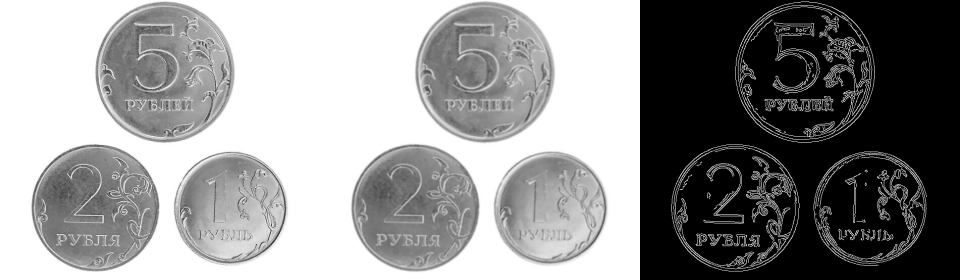

Слева исходное фото, справа фото с разметкой.


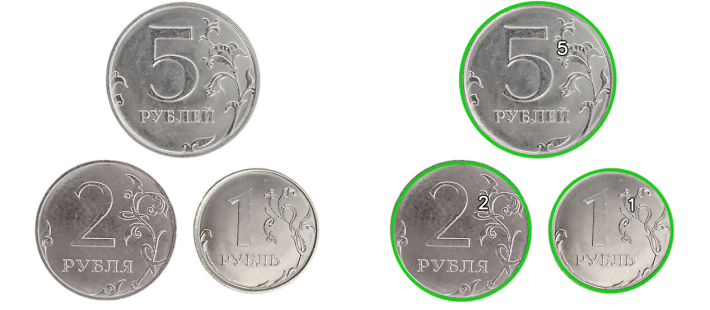


Снимок 2
Масштаб: 15.76 пикс./мм
Найдено монет: 3. Номиналы: [1, 2, 5]
Общая сумма: 8 руб. При ручном подсчёте: 8 руб.
Слева направо показаны оттенки серого, размытие и границы Кэнни.


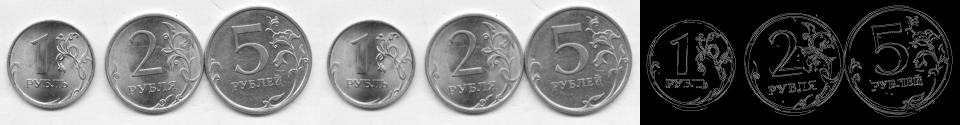

Слева исходное фото, справа фото с разметкой.


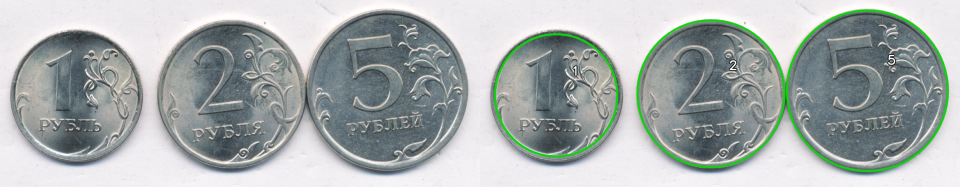


Снимок 3
Масштаб: 8.28 пикс./мм
Найдено монет: 6. Номиналы: [1, 1, 2, 2, 5, 5]
Общая сумма: 16 руб. При ручном подсчёте: 16 руб.
Слева направо показаны оттенки серого, размытие и границы Кэнни.


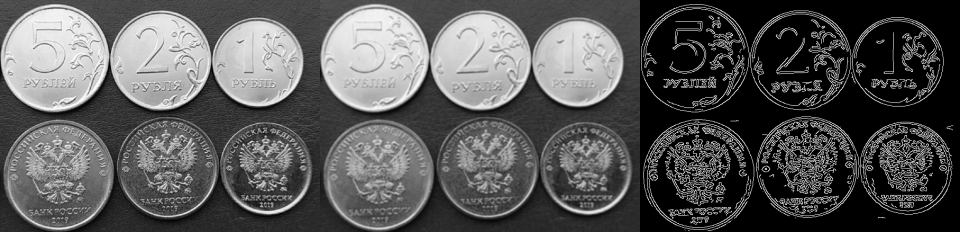

Слева исходное фото, справа фото с разметкой.


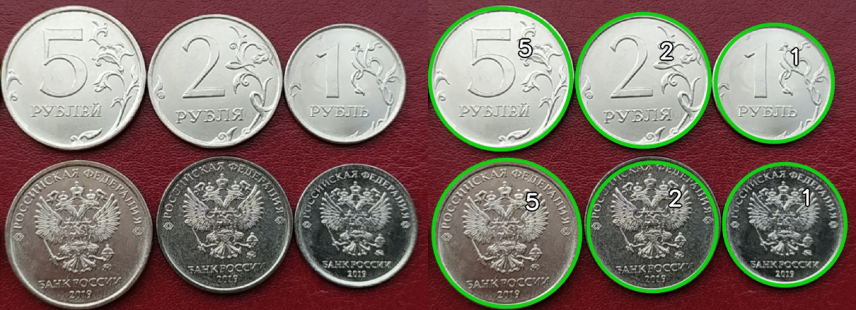

In [2]:
from base64 import b64encode


def show_images(images):
    h, w = images[0].shape[:2]
    scale = min(1, 960 / (w * len(images)), 310 / h)
    size = (max(1, round(w * scale)), max(1, round(h * scale)))
    panels = []

    for image in images:
        panels.append(cv.resize(image, size, interpolation=cv.INTER_AREA))

    row = cv.hconcat(panels)
    _, encoded = cv.imencode(".png", row)
    display({"image/png": b64encode(encoded).decode("ascii")}, raw=True)


for name, result in results.items():
    print(name)
    if "error" in result:
        print(result["error"])
        print()
        continue

    coins = result["coins"]
    print(f"Масштаб: {result['scale']:.2f} пикс./мм")
    if not coins:
        print("На фотографии не найдено окружностей.")
    print(f"Найдено монет: {len(coins)}. Номиналы: {sorted(coins)}")
    print(f"Общая сумма: {result['total']} руб. При ручном подсчёте: {result['expected']} руб.")
    print("Слева направо показаны оттенки серого, размытие и границы Кэнни.")
    show_images(result["stages"])
    print("Слева исходное фото, справа фото с разметкой.")
    show_images([result["photo"], result["marked"]])
    print()
